# Full weekly COVID reproduction — sMOA

Bộ paper **N=18.387/family, k=5, m=4.422**. 50 bang ×112 origins ×4 horizons = **22.400 targets/model**. GAM/GCV, **omit bridge**, NB 5.000 draws. **UQ matured:** chỉ earlier-issued forecast pairs có target date ≤ origin vào MLE, khớp `run_smoa.R:253`.

Giữ initialization `[20,10,6,0.3]`, frozen warmup và final revisions như main R. Do đó chưa gọi toàn bộ pipeline causal. Bridge omit vẫn là lựa chọn trước, khác main R; `experiment_0` riêng giữ UQ retrospective của Figure 2.

Notebook đọc `outputs/paper_full_nonconstant_v2_matured/`; BO vẫn ở `outputs/bo_gam_nonconstant_v2/02_optimization`, winner full tự chờ tại `outputs/bo_gam_full_nonconstant_v2_matured/`. Bản hồi cứu hoàn tất được giữ riêng ở `outputs/paper_full_nonconstant_v2/`. Các outputs hiển thị cũ đã được xóa để tránh lẫn policy.

[Xem protocol và nguồn R](FULL.md). Chạy lại các cells để đọc trạng thái và artifacts hiện có.


In [25]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiments/reproduction/run_full.py").exists())
RUN_DIR = ROOT / "outputs/paper_full_nonconstant_v2_matured"  # Đổi sang outputs/bo_gam_full_nonconstant_v2_matured khi muốn xem winner BO.
SELECTED_SERIES = "California"
def read_json(path):
    return json.loads(path.read_text()) if path.exists() else {}


In [26]:
pipeline = read_json(RUN_DIR / "pipeline.json")
config = read_json(RUN_DIR / "run_config.json")
display({k: v for k, v in pipeline.items() if k not in ["evaluation", "remaining_differences"]})
if config:
    display({k: config[k] for k in ["selection", "parameters", "states", "targets_per_model", "method"]})
    print("Weekly origins:", config["origins"][0], "->", config["origins"][-1], "; n =", len(config["origins"]))
else:
    display(Markdown("Run đang chờ hoặc chưa khởi tạo; chưa có kết quả full."))

{'status': 'complete',
 'started_utc': '2026-10-31T20:26:30.379350+00:00',
 'stages': [{'stage': 1,
   'name': 'Historical weekly archive',
   'artifact': '/Users/nguyentranglinh/infectious-disease-forecasting/outputs/paper_weekly_archive/manifest.csv',
   'origins': 112},
  {'stage': 2, 'name': 'UQ and prediction', 'artifact': '04_prediction'},
  {'stage': 3, 'name': 'Evaluation', 'artifact': '05_evaluation/report.md'}],
 'waiting_seconds': 1.9073486328125e-05,
 'execution_started_utc': '2026-10-31T20:26:32.533281+00:00',
 'parameters': {'N': 18387, 'k': 5, 'm': 4422, 'h': 4},
 'elapsed_seconds': 428.9426341056824,
 'finished_utc': '2026-10-31T20:33:39.322003+00:00',
 'publication_reproduction_complete': False}

{'selection': 'paper fixed parameters',
 'parameters': {'N': 18387, 'k': 5, 'm': 4422, 'h': 4},
 'states': 50,
 'targets_per_model': 22400,
 'method': {'models': ['smoa'],
  'smoothing': 'gam',
  'window_filter': 'nonconstant_v2',
  'coverage_quantiles': 23,
  'coverage_levels': 11,
  'interval_draws': 5000,
  'seed': 13,
  'bridge_mode': 'omit',
  'uq_policy': 'matured',
  'score_truth': 'raw final',
  'calibration_truth': 'final matured outcomes',
  'prehistory': 'frozen first scored vintage, as in upstream early-error initialization; retrospective warmup'}}

Weekly origins: 2020-08-15 -> 2022-10-01 ; n = 112


In [27]:
summary = read_json(RUN_DIR / "05_evaluation/summary.json")
if summary:
    metrics = pd.DataFrame(summary["models"]).T
    display(metrics[[c for c in ["mae", "wis", "coverage_50", "coverage_80", "coverage_95"] if c in metrics]])
    print("Targets/model:", summary["forecasts_per_model"])
    display(pd.DataFrame([{"horizon": int(h), "model": model, **values} for h, models in summary["by_horizon"].items() for model, values in models.items()]))
else:
    display(Markdown("Chưa có evaluation full. Không diễn giải điểm của một vài bang thành kết quả toàn bộ."))

,mae,wis,coverage_50,coverage_80,coverage_95
smoa,7384.661652,4747.378356,0.559018,0.777857,0.871696


Targets/model: 22400


,horizon,model,n,mae,wis
0,1,smoa,5600,4173.930357,2628.442657
1,2,smoa,5600,6273.882946,4008.564262
2,3,smoa,5600,8808.290536,5655.202296
3,4,smoa,5600,10282.542768,6697.304209


States predicted: 50 / 50


,series,origins,warmup_origins,history_mode,scored_start,scored_end,output_subdir,mae,wis,coverage_50,coverage_80,coverage_95,width_95,sharpness,overprediction,underprediction
4,California,112,24,as_of,2020-08-15,2022-10-01,5,44074.308036,28596.403049,0.582589,0.808036,0.908482,219561.924665,10344.024589,3700.515354,14551.863106


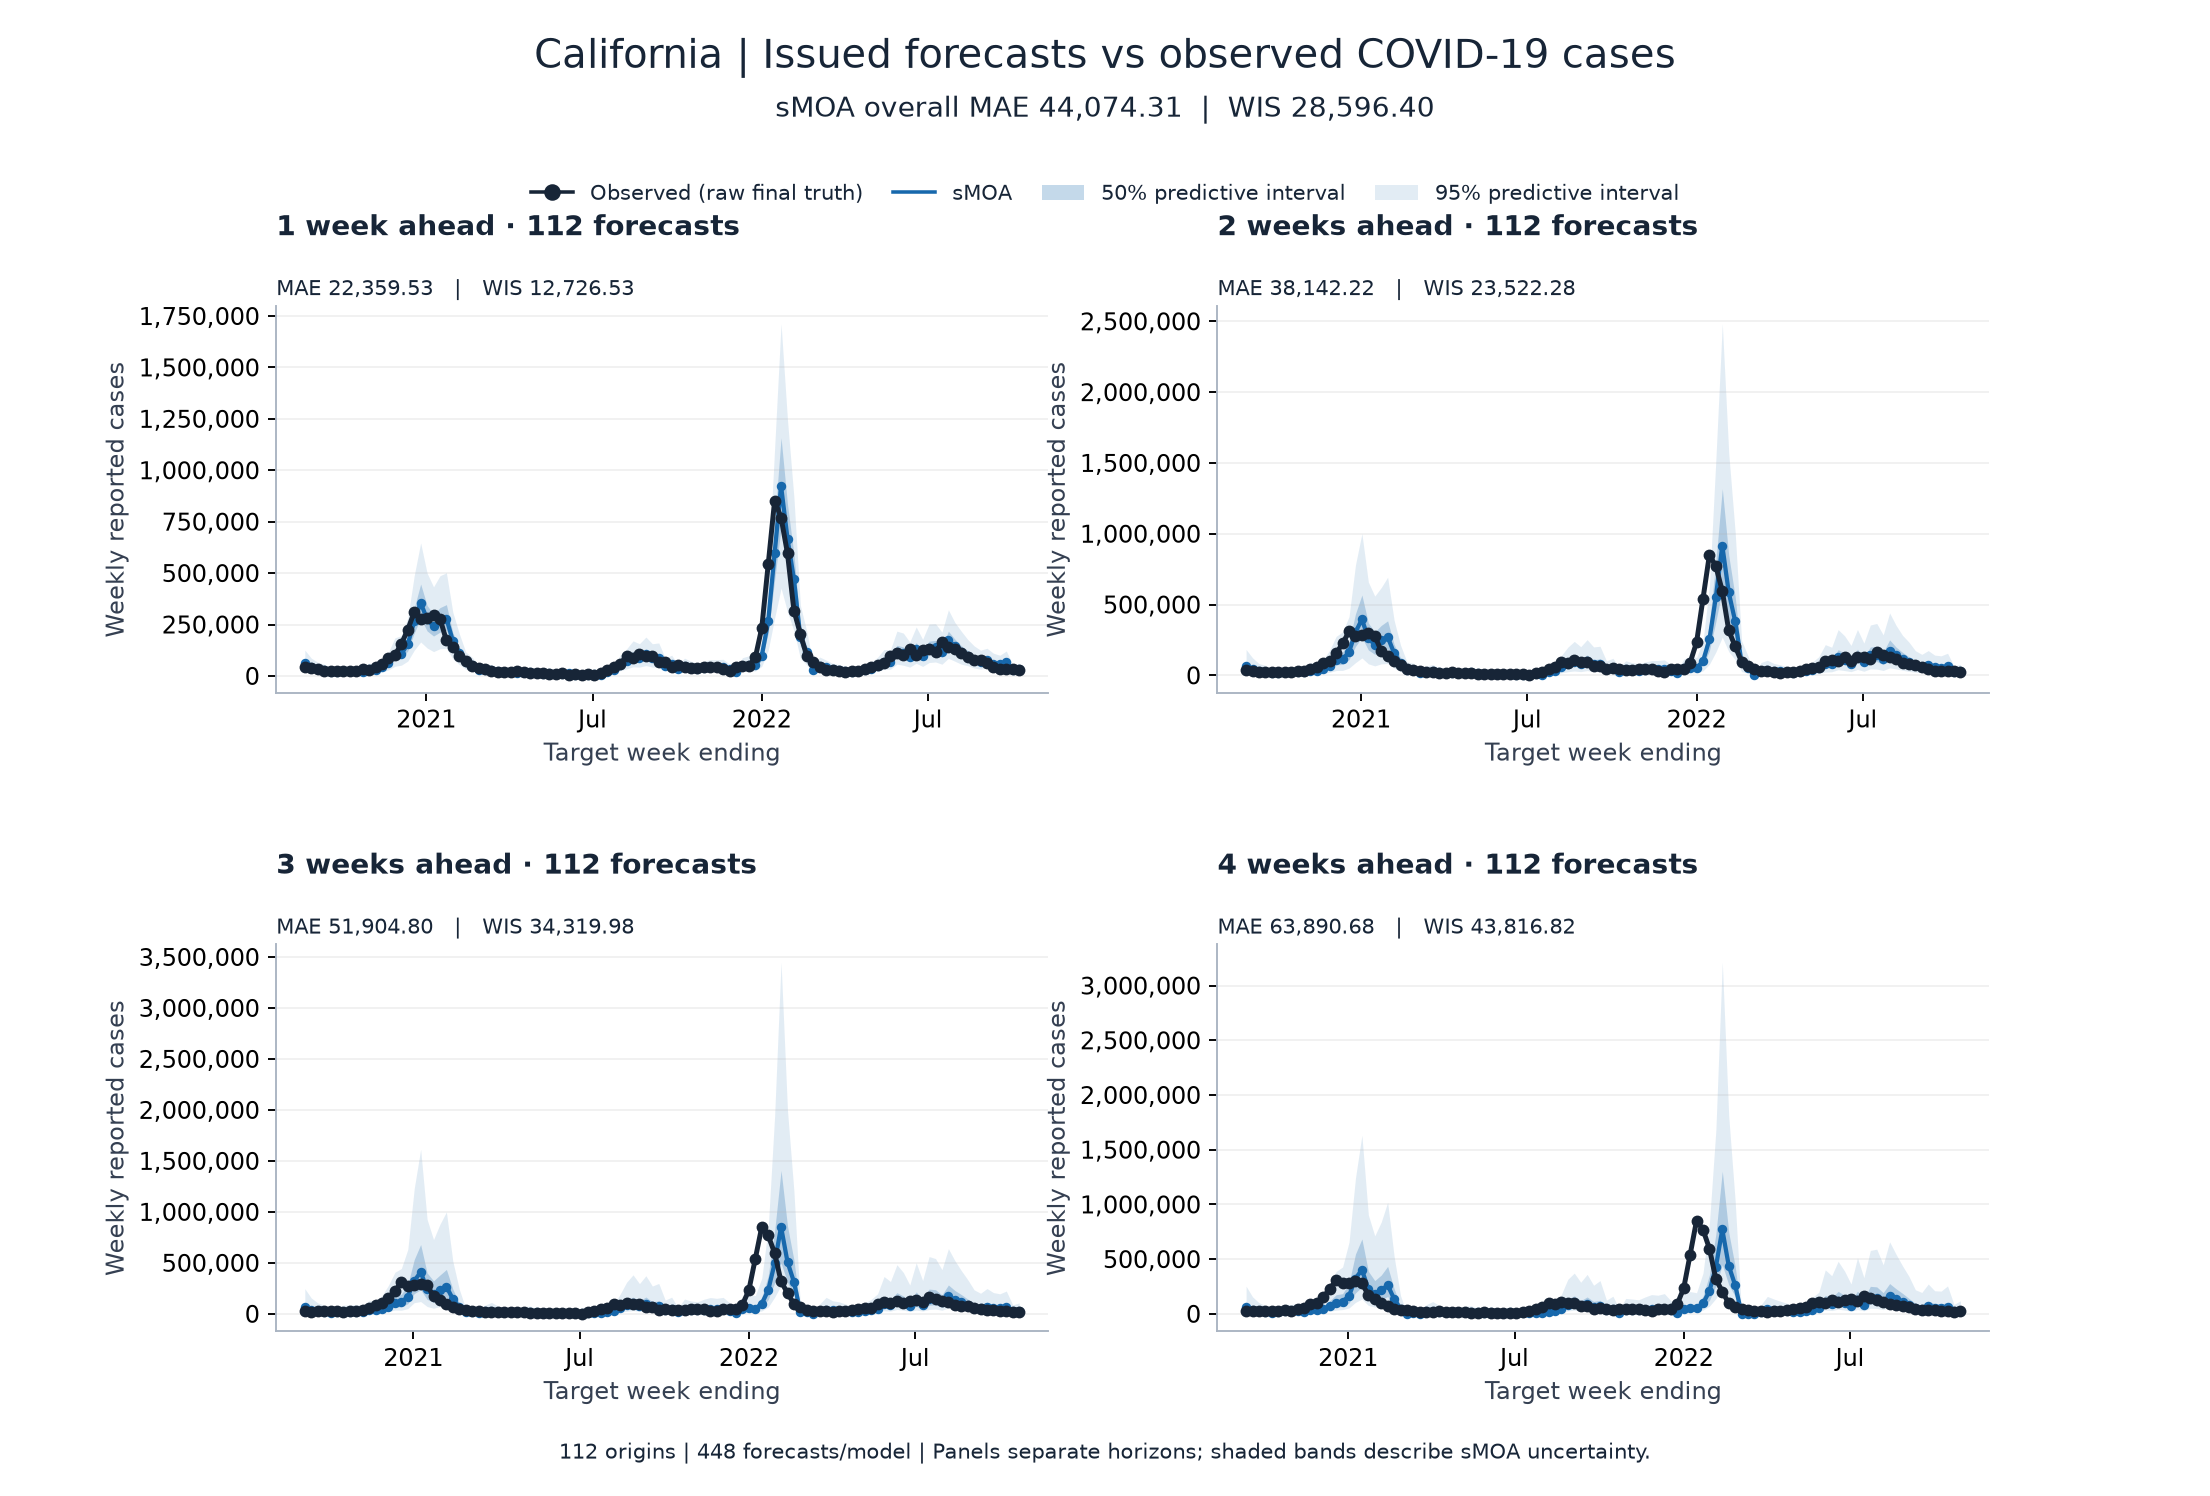

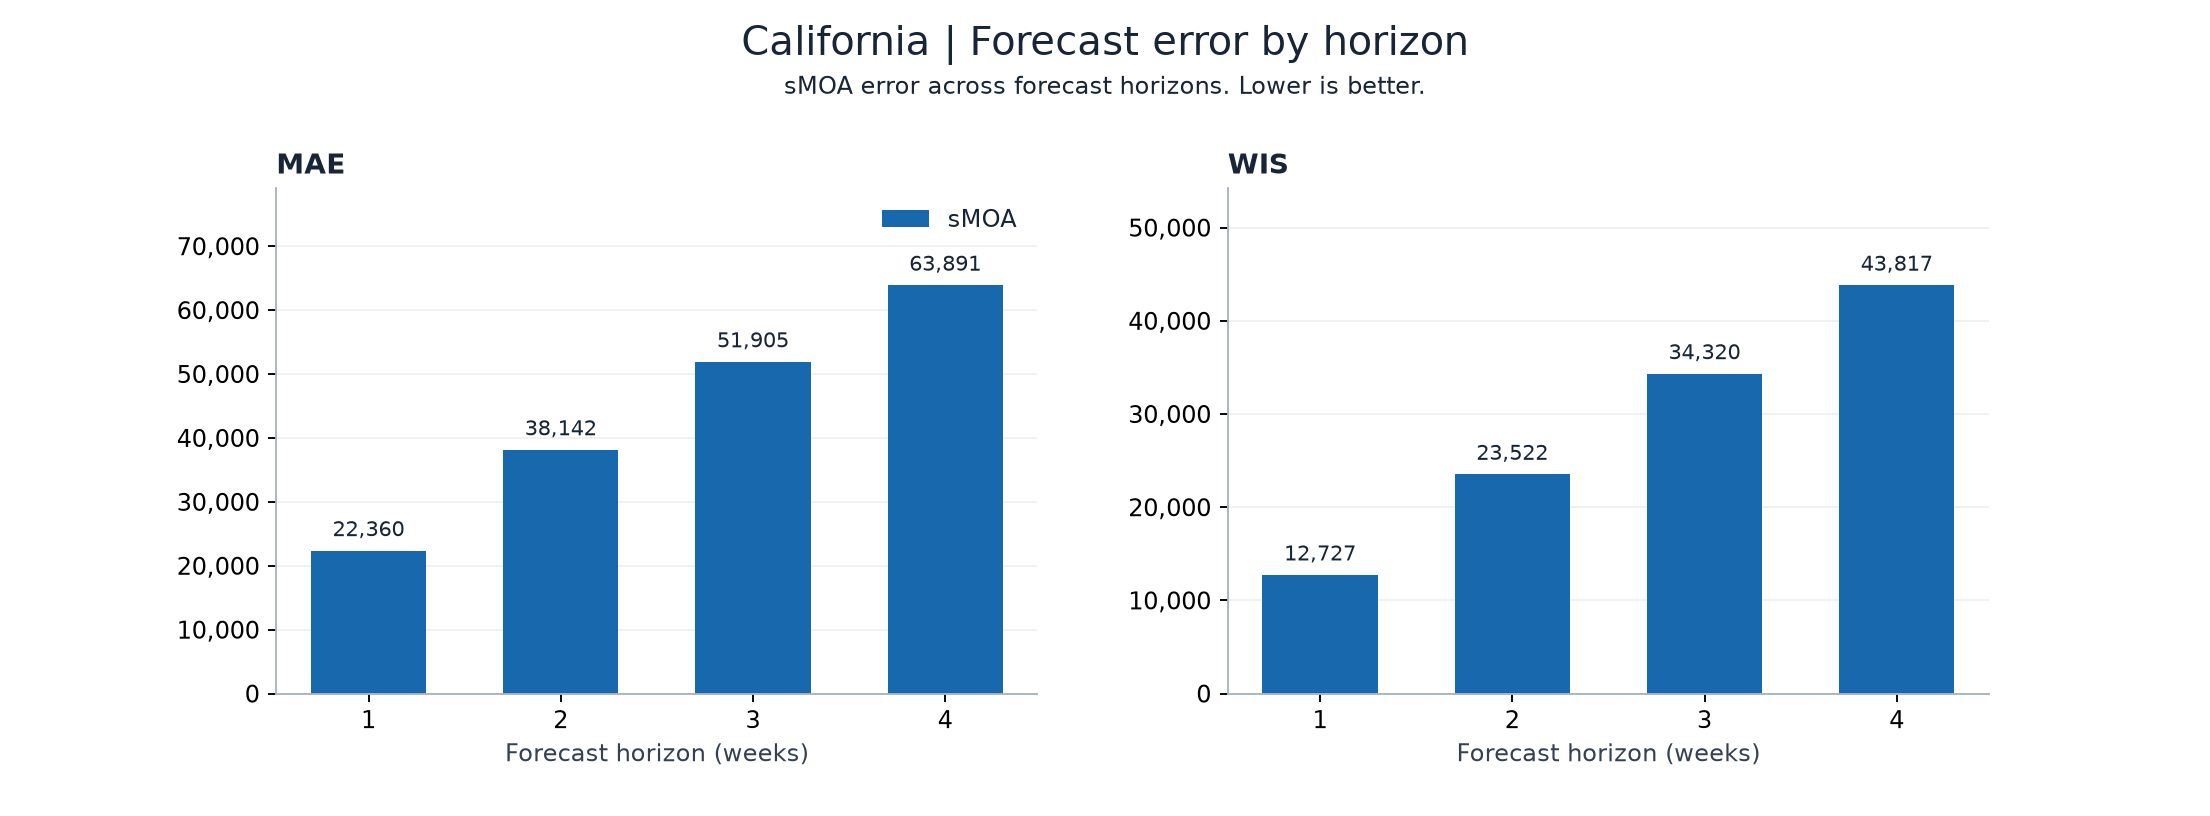

In [28]:
mapping_path = RUN_DIR / "04_prediction/series_metrics.csv"
selected_subdir = None
if mapping_path.exists():
    mapping = pd.read_csv(mapping_path)
    print("States predicted:", len(mapping), "/ 50")
    selected = mapping.loc[mapping.series == SELECTED_SERIES]
    if len(selected) == 1:
        selected_subdir = str(selected.iloc[0].output_subdir).zfill(2)
        display(selected)
if selected_subdir:
    evaluation = RUN_DIR / "05_evaluation" / selected_subdir
    for name in ["forecast_vs_actual", "metrics_by_horizon"]:
        path = evaluation / f"{name}.png"
        if path.exists():
            display(Image(filename=str(path)))
        else:
            display(Markdown(f"{SELECTED_SERIES}: hình {name} chưa được tạo."))
else:
    display(Markdown(f"Chưa có predictions hoàn tất của {SELECTED_SERIES}."))

In [29]:
if selected_subdir:
    prediction_dir = RUN_DIR / "04_prediction" / selected_subdir
    issued = pd.read_csv(prediction_dir / "predictions.csv")
    origin = issued.forecast_origin.max()
    display(issued.loc[issued.forecast_origin == origin])
    calibration = pd.read_csv(prediction_dir / "calibration.csv")
    display(calibration.loc[(calibration.model == "smoa") & (calibration.forecast_origin == origin)])
    quantiles = pd.read_csv(prediction_dir / "quantiles.csv")
    selected_q = quantiles.loc[(quantiles.model == "smoa") & (quantiles.forecast_origin == origin)]
    display(selected_q.pivot(index="horizon", columns="quantile", values="value"))

,series,forecast_origin,target_end_date,horizon,forecast,forecast_date
444,California,2022-10-01,2022-10-08,1,32154.0,2022-10-03
445,California,2022-10-01,2022-10-15,2,31018.0,2022-10-03
446,California,2022-10-01,2022-10-22,3,30205.5,2022-10-03
447,California,2022-10-01,2022-10-29,4,29182.5,2022-10-03


,series,forecast_origin,horizon,model,nb_size,method,calibration_n,excluded_negative,calibration_policy,future_calibration_n
444,California,2022-10-01,1,smoa,8.494250,mle,135,0,matured,0
445,California,2022-10-01,2,smoa,3.140436,mle,134,0,matured,0
446,California,2022-10-01,3,smoa,1.225900,mle,133,0,matured,0
447,California,2022-10-01,4,smoa,1.000000,mle,132,0,matured,0


quantile,0.010,0.025,0.050,0.100,0.150,0.200,0.250,0.300,0.350,0.400,...,0.600,0.650,0.700,0.750,0.800,0.850,0.900,0.950,0.975,0.990
horizon,,,,,,,,,,,,,,,,,,,,,
1,13290.97,15521.600,17345.65,20161.2,22156.80,23720.2,25193.25,26644.4,28027.60,29374.8,...,35000.6,36543.70,38164.3,39920.00,42034.0,44946.15,48159.2,53576.70,59260.425,65926.47
2,8264.38,9789.100,12168.00,14876.4,16974.70,19189.9,21211.50,23176.9,24970.75,26930.1,...,35595.9,38295.70,41155.4,44316.75,47974.1,52717.45,58674.8,68593.20,77986.175,90607.72
3,8469.87,9211.975,10428.65,12509.8,14471.05,16254.6,18322.00,20324.5,22411.20,24862.6,...,36148.6,39965.75,43962.9,49190.75,55137.8,63188.20,73658.9,90722.25,106975.975,126803.62
4,9882.00,10309.625,11063.75,12700.8,14179.25,15844.4,17585.50,19580.9,21753.65,24001.8,...,35657.2,39873.55,44353.8,48820.00,55227.2,64724.50,76308.7,98965.00,119493.875,145154.09


In [30]:
bo_dir = ROOT / "outputs/bo_gam_nonconstant_v2/02_optimization"
bo_meta = read_json(bo_dir / "metadata.json")
print("BO selection status:", bo_meta.get("status", "not_started"))
if bo_meta.get("status") == "complete":
    display(read_json(bo_dir / "best_params.json"))
else:
    display(read_json(bo_dir / "progress.json"))
followup = read_json(ROOT / "outputs/bo_gam_full_nonconstant_v2_matured/pipeline.json")
print("Full COVID rerun with BO winner:", followup.get("status", "not_started"))
comparison = ROOT / "outputs/bo_gam_full_nonconstant_v2_matured/paper_comparison/comparison.csv"
if comparison.exists():
    display(pd.read_csv(comparison))

BO selection status: running


{'status': 'running',
 'trial': 6,
 'phase': 'gam_preprocessing',
 'completed_curves': 31,
 'total_curves': 48}

Full COVID rerun with BO winner: waiting_for_bo
